# Get to Know a Dataset: Thal-Kak Multiple Sequence Alignment Databases

This notebook serves as a guided tour of the [Thal-Kak Multiple Sequence Alignment Databases](https://registry.opendata.aws/thal-kak-msa/) dataset.

The dataset is a collection of prebuilt protein sequence databases for multiple sequence alignment (MSA) search. An MSA lines up a protein with its homologs. It is the main input of protein structure prediction, and it is also used to study conservation, coevolution and protein function. The nine databases here derive from UniProt UniRef100, the reduced BFD, MGnify, EnVhogDB and the Logan protein catalogue.

The databases are set up for [Thal-Kak](https://github.com/CSSB-SNU/Thal-Kak), a pipeline that unifies several structure prediction models. Its local MSA search reads them and writes MSAs in the input format of those models. They complement the databases that [ColabFold](https://github.com/sokrypton/ColabFold) provides, UniRef30 and ColabFoldDB, which the ColabFold MSA server searches. Thal-Kak also searches ColabFold's UniRef30, which the Steinegger lab distributes, together with the databases here.

Searching these databases needs hundreds of gigabytes of memory and disk, so this notebook does not run a search. It shows how the bucket is organized, how to install the databases, and what a search returns, using an MSA that Thal-Kak built for a CASP17 target. The full documentation is [here](https://github.com/CSSB-SNU/Thal-Kak/tree/main/aws_open_data).

### Q: How have you organized your dataset? Help us understand the key prefix structure of your S3 bucket.

The bucket holds nine databases, one `.tar.zst` archive each. At the top level there are:

1. `README.md`, the dataset documentation, and `LICENSE.txt`, which gives the license, attribution, citation and changes for each database.
2. `mmseqs/`, with one archive per MMseqs2 database.
3. `hhblits/`, with one archive per HH-suite database.

Each archive holds one complete database built from one upstream source. It is named after the database's key, the name Thal-Kak's installer uses for it. The archives are the same files as on our [Hugging Face repository](https://huggingface.co/datasets/cssbsnu/Thal-Kak_local_db), and their SHA-256 checksums are listed in Thal-Kak's installer manifest. A search needs a whole database, so one archive is the unit of download.

| Archive | Source | Download | Extracted |
|---|---|--:|--:|
| `mmseqs/mgnify_clusters.tar.zst` | MGnify 2024_04 | 126.9 GiB | 202.3 GiB |
| `mmseqs/envhog_std.tar.zst` | EnVhogDB | 20.7 GiB | 36.7 GiB |
| `mmseqs/bfd_reduced.tar.zst` | BFD, reduced subset | 18.6 GiB | 27.6 GiB |
| `mmseqs/logan_human.tar.zst` | Logan v1, SRA runs annotated as human | 12.0 GiB | 28.1 GiB |
| `hhblits/uniref100_2026_01.tar.zst` | UniProt UniRef100 2026_01 | 157.2 GiB | 1,301.5 GiB |
| `hhblits/mgnify_clusters.tar.zst` | MGnify 2024_04 | 33.7 GiB | 150.3 GiB |
| `hhblits/logan_nonhuman.tar.zst` | Logan v1, all other SRA runs | 24.2 GiB | 55.9 GiB |
| `hhblits/envhog.tar.zst` | EnVhogDB | 4.7 GiB | 11.5 GiB |
| `hhblits/logan_human.tar.zst` | Logan v1, SRA runs annotated as human | 0.8 GiB | 2.0 GiB |
| **Total** | | **398.9 GiB** | **1,815.9 GiB** |

These are derived databases. The sequences of UniRef100, MGnify and the reduced BFD were re-clustered, EnVhogDB was re-clustered at its upstream `standard` level, and Logan was built into an MMseqs2 expandable-profile database; `hhblits/envhog` is upstream's own HH-suite build. `LICENSE.txt` records what was done to each.

Thal-Kak's default MMseqs2 search (`mmseqs_local`) also uses two databases that are not in this bucket. UniRef30 2023_02 is the ColabFold build that the Steinegger lab distributes at `opendata.mmseqs.org`. The MMseqs2 build of UniRef100 2026_01 is on our [Hugging Face repository](https://huggingface.co/datasets/cssbsnu/Thal-Kak_local_db). The installer fetches each from there.

In [1]:
# This notebook requires the following additional library
# (please install using the preferred method for your environment, e.g. pip, conda):
#
# boto3 >= 1.34

# Built-ins
import re
from pathlib import Path
from urllib.request import urlopen
# Installed libraries
import boto3
from botocore import UNSIGNED
from botocore.config import Config
from IPython.display import Image, display

Next, we create an S3 client and list every object in the bucket with its size. The bucket is public, so the client does not sign its requests and no AWS account is needed.

In [2]:
# Location of the S3 bucket for this dataset
bucket = "thal-kak-msa"

# The bucket is public, so requests are not signed.
s3 = boto3.client("s3", region_name="us-east-1", config=Config(signature_version=UNSIGNED))

for obj in s3.list_objects_v2(Bucket=bucket)["Contents"]:
    size = obj["Size"]
    shown = f"{size / 2**30:,.1f} GiB" if size >= 2**27 else f"{size / 2**10:,.0f} KiB"
    print(f"{obj['Key']:<36}{shown:>12}")

LICENSE.txt                               13 KiB
README.md                                 11 KiB
hhblits/envhog.tar.zst                   4.7 GiB
hhblits/logan_human.tar.zst              0.8 GiB
hhblits/logan_nonhuman.tar.zst          24.2 GiB
hhblits/mgnify_clusters.tar.zst         33.7 GiB
hhblits/uniref100_2026_01.tar.zst      157.2 GiB
mmseqs/bfd_reduced.tar.zst              18.6 GiB
mmseqs/envhog_std.tar.zst               20.7 GiB
mmseqs/logan_human.tar.zst              12.0 GiB
mmseqs/mgnify_clusters.tar.zst         126.9 GiB


### Q: What data formats are present in your dataset? What kinds of data are stored using these formats? Can you give any advice for how you work with these data formats?

**The databases.** Each database is stored in the native format of the tool that searches it.

- The `mmseqs/` archives hold [MMseqs2](https://github.com/soedinglab/MMseqs2) databases. MMseqs2 searches one consensus sequence per cluster, then expands every cluster it hits to its member sequences, which are aligned to the query and filtered before they join the MSA.
- The `hhblits/` archives hold [HH-suite](https://github.com/soedinglab/hh-suite) databases. For each cluster they keep an MSA and a compact summary that HHblits scans first to pick candidates, and for some clusters a precomputed profile hidden Markov model; HHblits builds the others from the MSA.

**The output.** A search returns an MSA in A3M format, a FASTA-like text file. The first record is the query, and each following record is a hit aligned to it. Uppercase letters and `-` line up with query positions; lowercase letters are insertions that the query does not have. Thal-Kak writes one A3M per chain and passes them to its structure prediction models. The next section loads one.

**Why these formats.** MMseqs2 and HH-suite are among the most widely used tools for MSA search: ColabFold builds its MSAs with MMseqs2, and AlphaFold 2 searched BFD and Uniclust30 with HHblits. Choosing these tools fixed the formats, since each tool searches its own database format.

**Advice.**

- **Search from local disk, not from S3.** Download and extract the archives you need first. The MMseqs2 prefilter reads its whole index on every search, and HHblits makes many small random reads.
- **Install with Thal-Kak's `install_db.sh`.** We strongly recommend it over setting the databases up by hand. It checks each archive's SHA-256, extracts it, arranges the files the way Thal-Kak expects, builds the MMseqs2 search index, and removes 9 empty records from the `uniref100_2026_01` cs219 index that can crash HHblits. Each of these steps is easy to miss by hand.

### Q: Can you show us an example of downloading and loading data from your dataset?

**Downloading.** Install the databases with `install_db.sh` from Thal-Kak. It downloads the archives from this bucket, needs no AWS account, and does every setup step listed above.

```bash
git clone https://github.com/CSSB-SNU/Thal-Kak.git
cd Thal-Kak
# create and activate the project environment first — it provides
# zstd, aria2c and mmseqs, which the installer calls.

./install_db.sh --family mmseqs                        # every MMseqs2 database Thal-Kak uses
./install_db.sh --family hhblits envhog logan_human    # selected HH-suite databases
./install_db.sh --family template                      # template snapshot for the default search
./install_db.sh --family mmseqs --status               # what is already installed
```

The archives range from 0.8 GiB to 157.2 GiB and extract to 1.77 TiB in total, so this notebook does not download them.

**Searching.** Once the databases are installed, one command builds the MSA for a FASTA file. `--stoi` gives the stoichiometry, here one copy of chain A:

```bash
thalkak msa --msa mmseqs_local --seq T2455.fasta --stoi A1
```

By default the search also looks for structural templates, which needs the template snapshot installed above (80.5 GiB, from our Hugging Face repository). To build only the MSA, turn template search off in the MSA config (`template.enable: false`).

Thal-Kak then writes:

- `T2455.a3m`, the MSA of all chains together
- `T2455_unpaired_msa_chains_a.a3m`, one MSA per distinct chain (heteromers also get paired MSAs)
- `T2455.yaml`, which the structure prediction stage reads
- `plots/`, with a coverage plot and a depth (Neff) plot for each distinct chain

**Loading the result.** Below we load the per-chain MSA that Thal-Kak built in July 2026 for CASP17 target T2455, a single chain of 299 residues. The file ships with this notebook in the Thal-Kak repository.

In [3]:
# The example MSA ships with this notebook in the Thal-Kak repository.
REPO_FILES = "https://raw.githubusercontent.com/CSSB-SNU/Thal-Kak/main/aws_open_data"


def repo_file(path):
    """A file next to this notebook, fetched from GitHub when the notebook runs elsewhere."""
    local = Path(path)
    return local.read_bytes() if local.exists() else urlopen(f"{REPO_FILES}/{path}").read()


a3m = repo_file("examples/T2455_unpaired_msa_chains_a.a3m").decode()

records = []  # [header, sequence] pairs
for line in a3m.splitlines():
    if line.startswith(">"):
        records.append([line[1:], ""])
    elif records:
        records[-1][1] += line.strip()

print(f"{len(records):,} sequences, the query included")

2,799 sequences, the query included


The first record is the query, which Thal-Kak labels `101`. A hit's header holds its ID followed by nine tab-separated alignment statistics: the score in bits, the sequence identity, the E-value, the start and end of the alignment on the query, the query length, the start and end on the hit, and the hit length. Positions count from 0. Here are the first three records, cut to 100 characters:

In [4]:
for header, sequence in records[:3]:
    print(">" + header)
    print(sequence[:100] + "...")

>101
AFRPISVFREANEDESGFTCCAFSARERFLMLGTCTGQLKLYNVFSGQEEASYNCHNSAITHLEPSRDGSLLLTSATWSQPLSALWGMKSVFDMKHSFTE...
>UniRef100_UPI001CF77234	287	0.916	1.340E-82	1	298	299	1064	1373	1496
-FRPISVFREANEDESGFTCCAFSARERFLMLGTCTGHLKLYNVFSGQEEASYKCHNSAITHLEPSRDGSLLLTSASWSQPLSALWGMKSVFETKHSFTD...
>UniRef100_UPI0008FEC54E	286	0.945	1.834E-82	1	298	299	1084	1393	1512
-FRPISVFREANEDESGFTCCAFSARERFLMLGTCTGQLKLYNVFSGQEEASYNCHNSAITHLEPSRDGSLLLTSATWSQPLSALWGMKSVFDMKHSFTE...


Deleting the lowercase letters, the insertions, turns the A3M into an aligned matrix with one column per query position, the form most tools take:

In [5]:
aligned = [re.sub("[a-z]", "", sequence) for _, sequence in records]
print(f"{len(aligned):,} rows x {len(aligned[0])} columns")

2,799 rows x 299 columns


### Q: A picture is worth a thousand words. Show us a visual (or several!) from your dataset that either illustrates something informative about your dataset, or that you think might excite someone to dig in further.

Most of these databases come from newer upstream releases than the ones the ColabFold MSA server searched when we compared them, so a query is searched against many more sequence clusters. The figure below is Fig. 1b of the Thal-Kak preprint. It counts the cluster representatives a query is searched against, with exact duplicates removed within and across databases:

- **UniRef.** The ColabFold MSA server searches UniRef30 2023_02, with 36.3 million representatives. Thal-Kak adds UniRef100 2026_01 to it, for 64.0 million together, 1.76 times as many.
- **Environmental and metagenomic.** The ColabFold MSA server searches ColabFoldDB 2021_08, with 209.3 million. Thal-Kak searches the four MMseqs2 databases in this bucket, built from releases up to 2025, for 435.8 million together, 2.08 times as many.

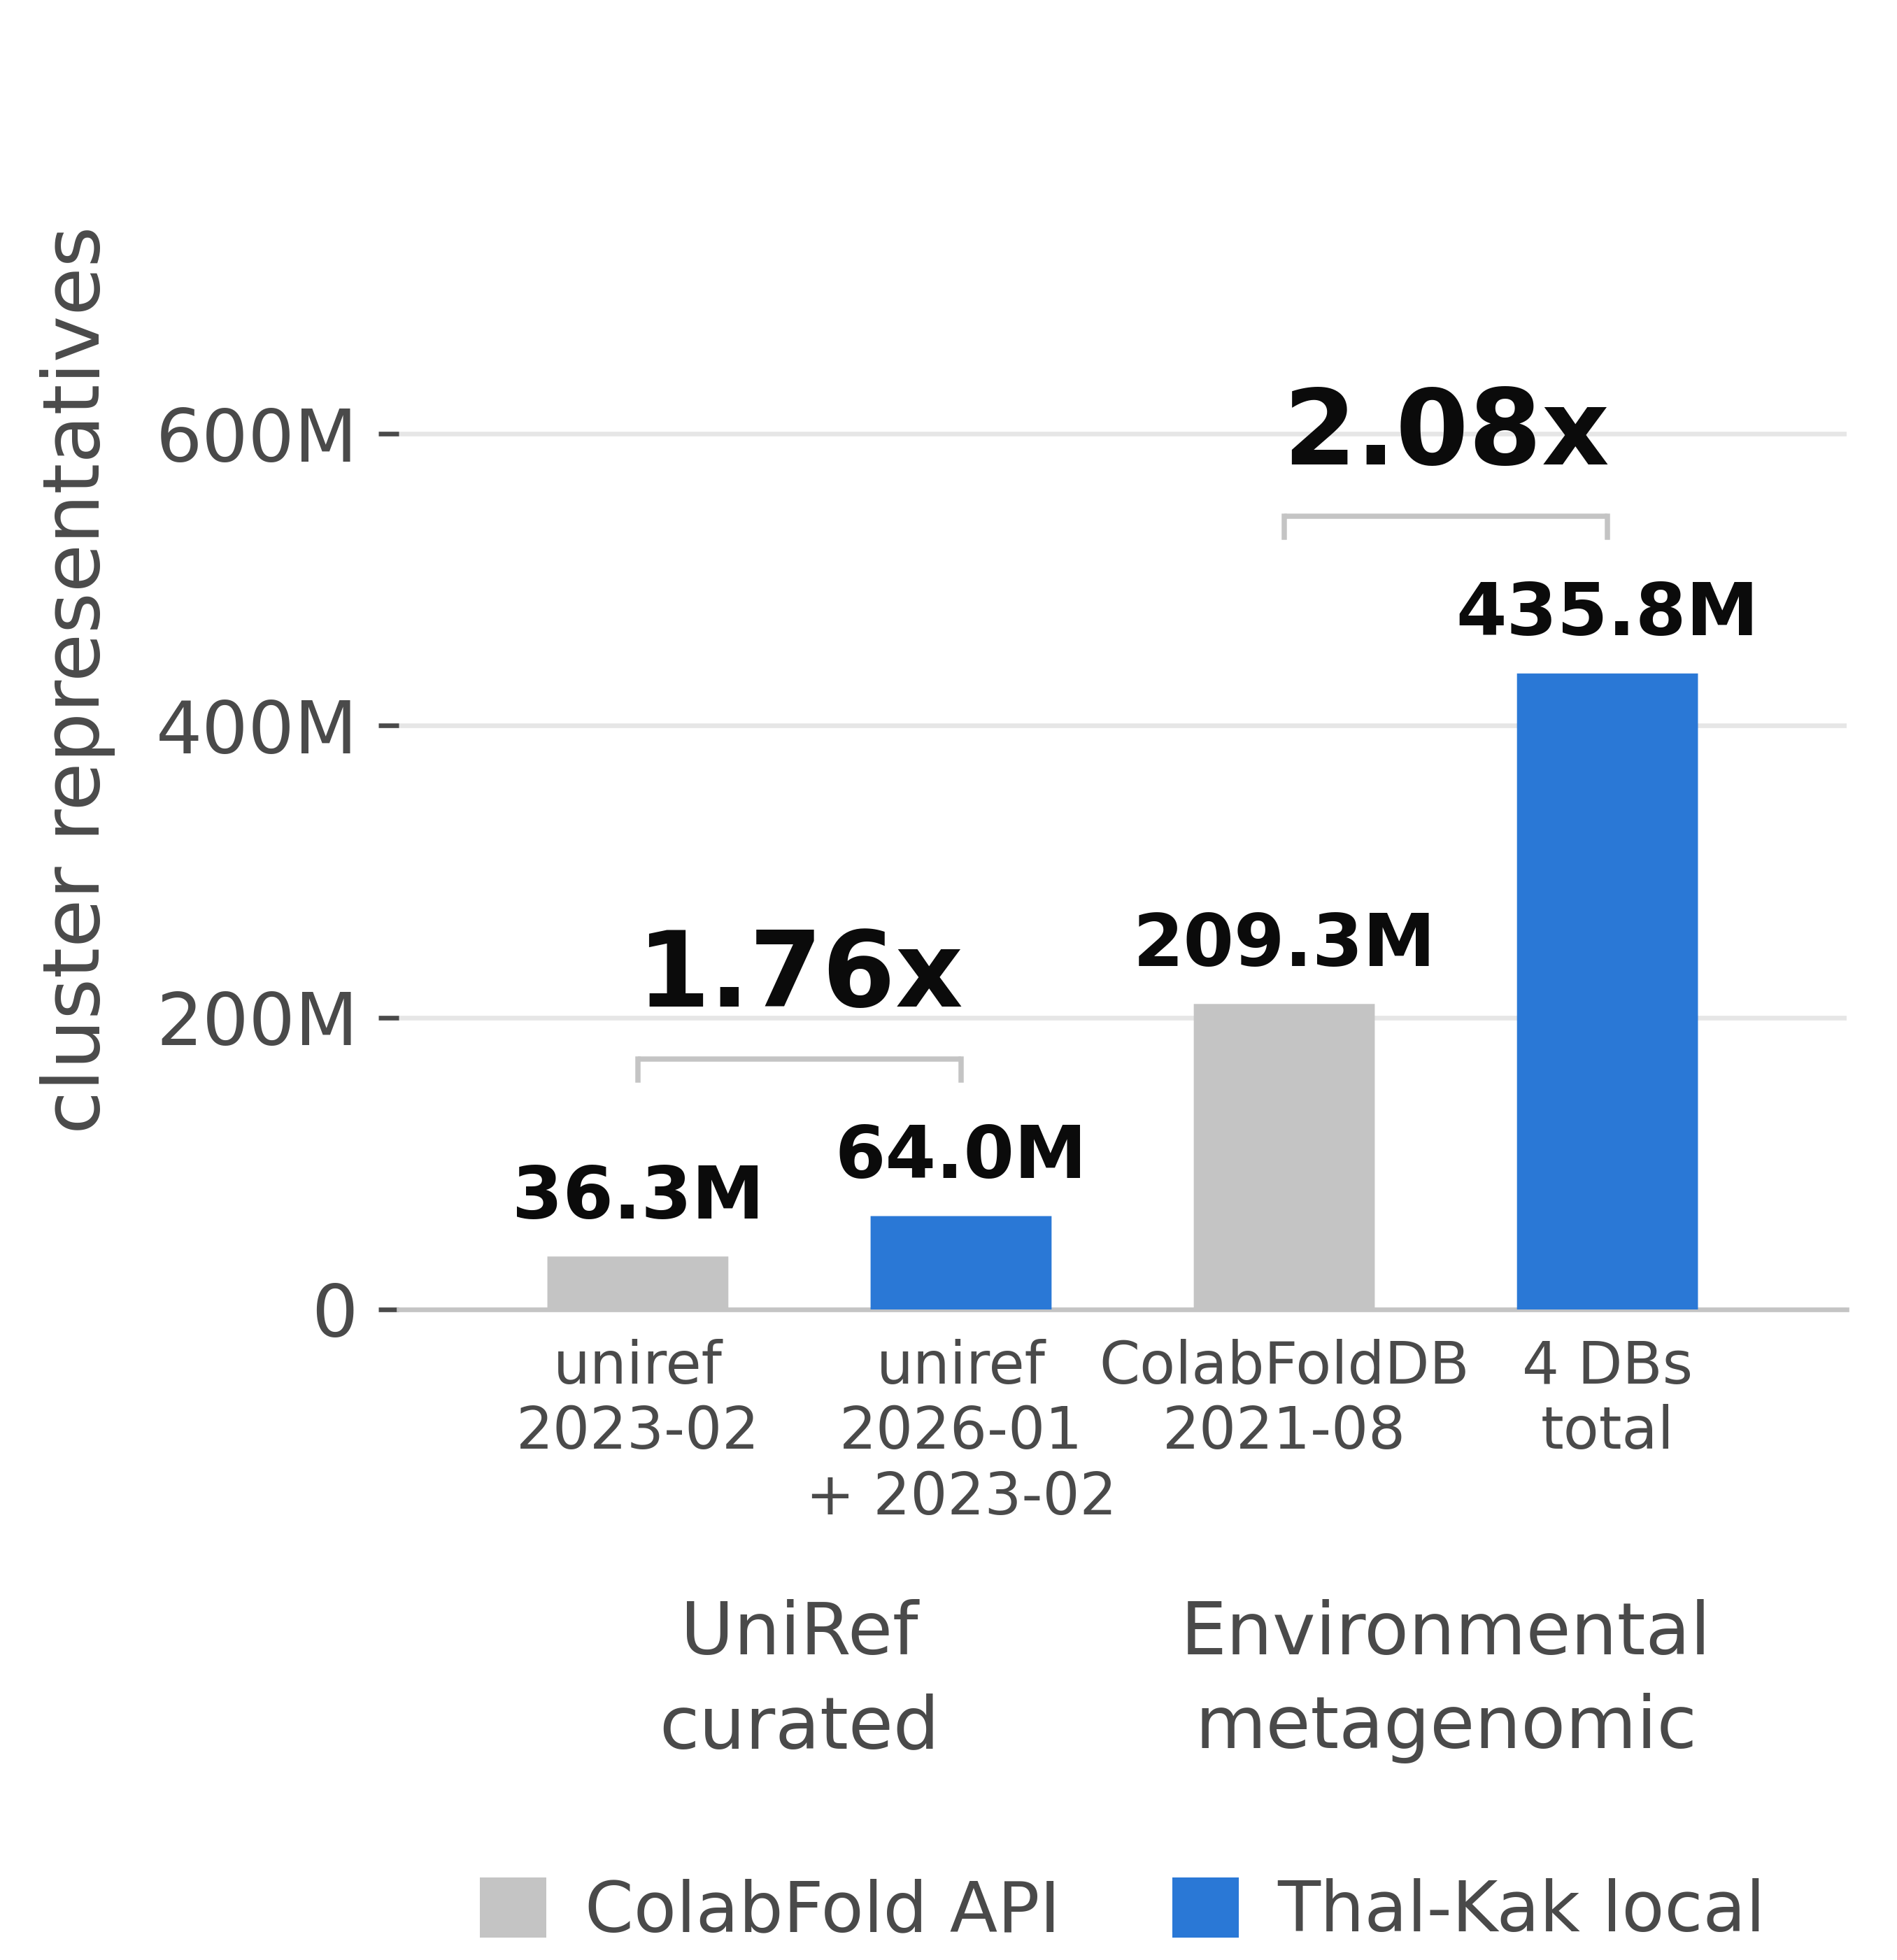

In [6]:
display(Image(data=repo_file("figures/fig1b_searchable_clusters.png"), width=420))

**Searchable cluster representatives per database group.** Grey, the ColabFold MSA server (ColabFoldDB counts from Mirdita et al. 2022); blue, Thal-Kak's local search. The counts are distinct cluster representatives, the entries the MMseqs2 prefilter scans, not the number of sequences stored.

Thal-Kak also draws a coverage plot of every chain's MSA in `plots/` after each search. Here is the one for the T2455 MSA loaded above:

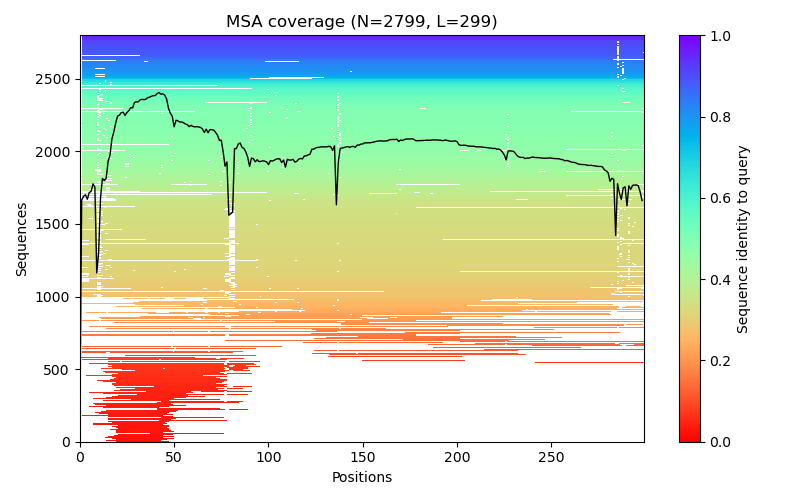

In [7]:
display(Image(data=repo_file("figures/T2455_coverage.png"), width=720))

How to read it:

- Each row is one sequence of the MSA. Its colour is the fraction of query positions where it has the same residue as the query, and rows are sorted by that fraction: purple rows match the query almost everywhere, red rows at few positions, because they are distant or because they are short.
- The x axis is the position in the query. White means that a sequence does not cover that position.

The red block at the bottom is a large group of short sequences that align only to roughly positions 10 to 75; they look red mainly because they cover so little of the query. Beside this plot, Thal-Kak draws the depth (Neff) of the MSA along the chain and records per-database counts in `neff_summary.json`.

### Q: What is one question that you have answered using these data? Can you show us how you came to that answer?

On FoldBench targets for which structure prediction had performed poorly, we used these data to obtain deeper MSAs, and some of those targets were then predicted more accurately.

The figures below are Supplementary Figs. 2b and 2c of the Thal-Kak preprint ([doi:10.64898/2026.08.19.745680](https://doi.org/10.64898/2026.08.19.745680)). Each point is one target. The x axis uses the MSA from the ColabFold MSA server; the y axis uses Thal-Kak's local MSA, searched against up-to-date databases including these. We do not rerun this here, because each MSA needs a full search of databases hundreds of gigabytes in size.

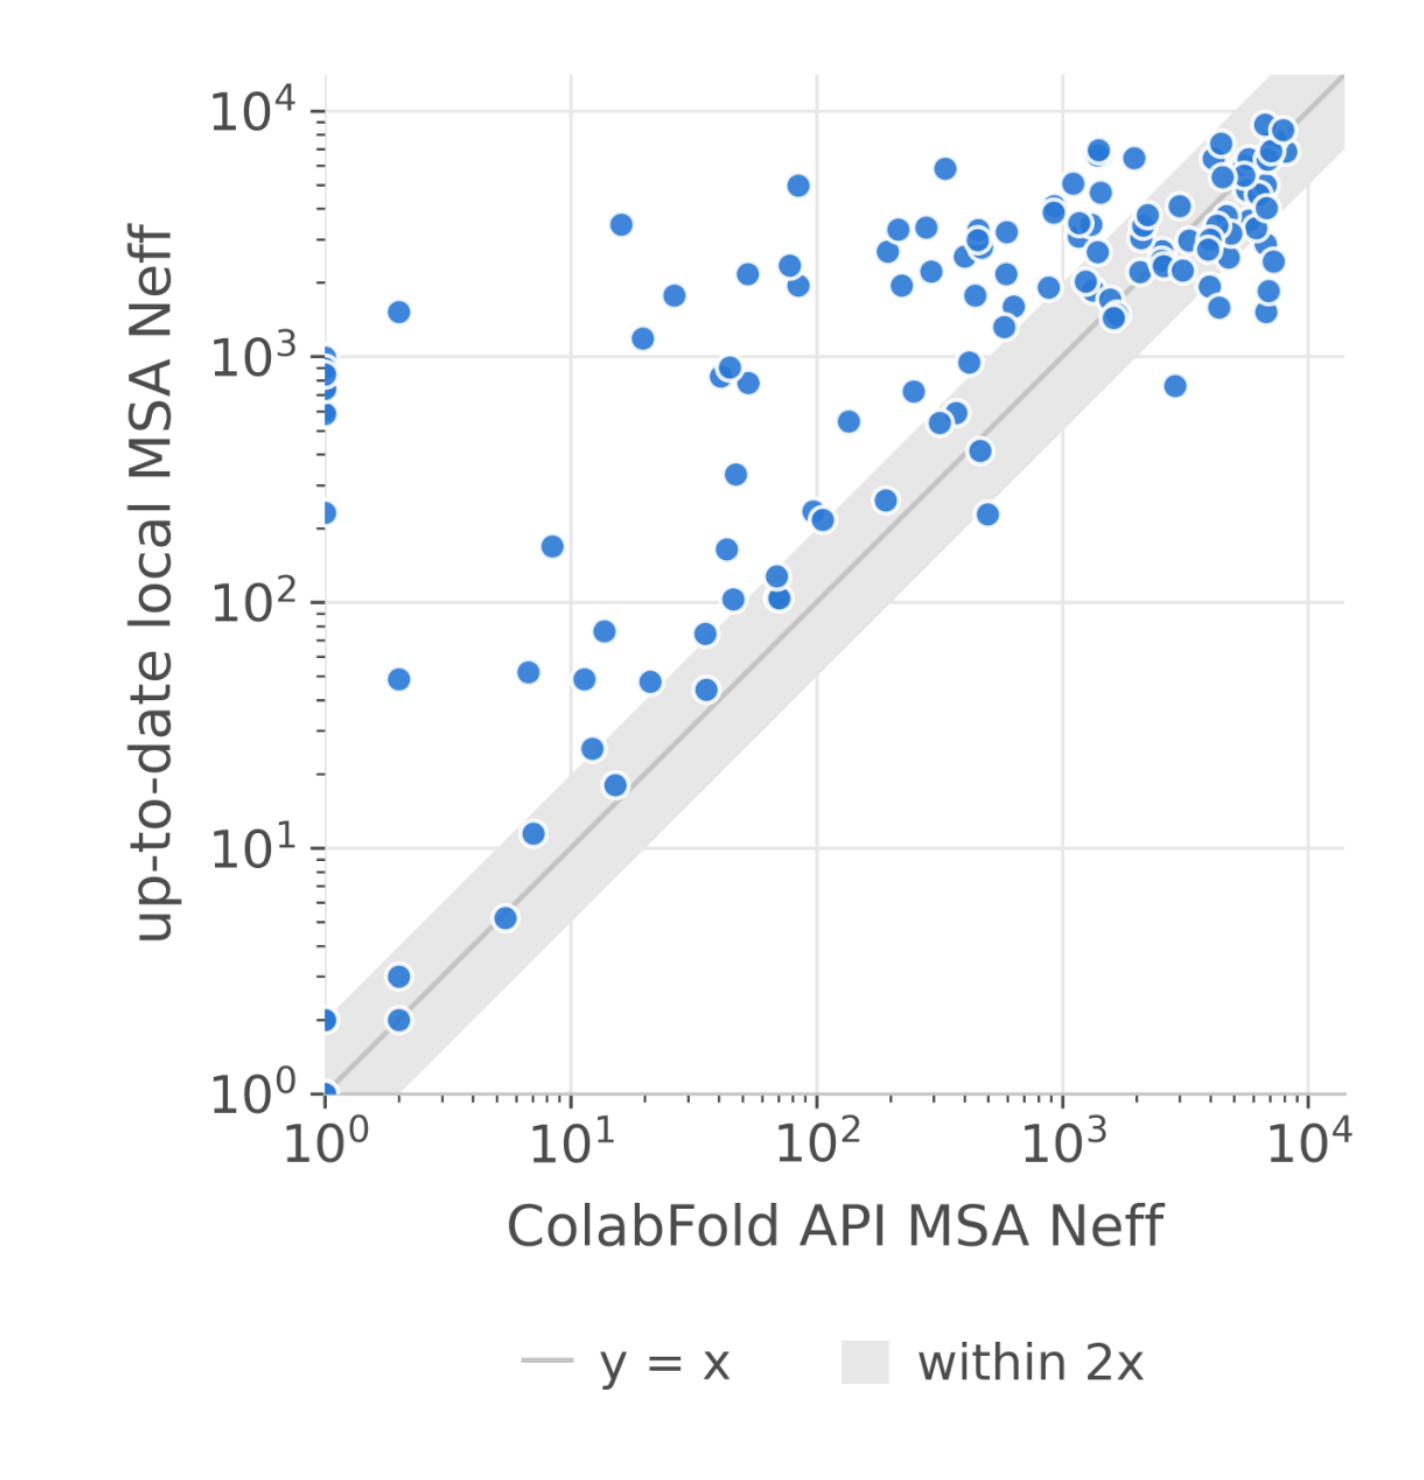

In [8]:
display(Image(data=repo_file("figures/supple_fig2b.png"), width=420))

**MSA depth.** Effective number of sequences (Neff) of each MSA. The grey band marks a difference within 2×.

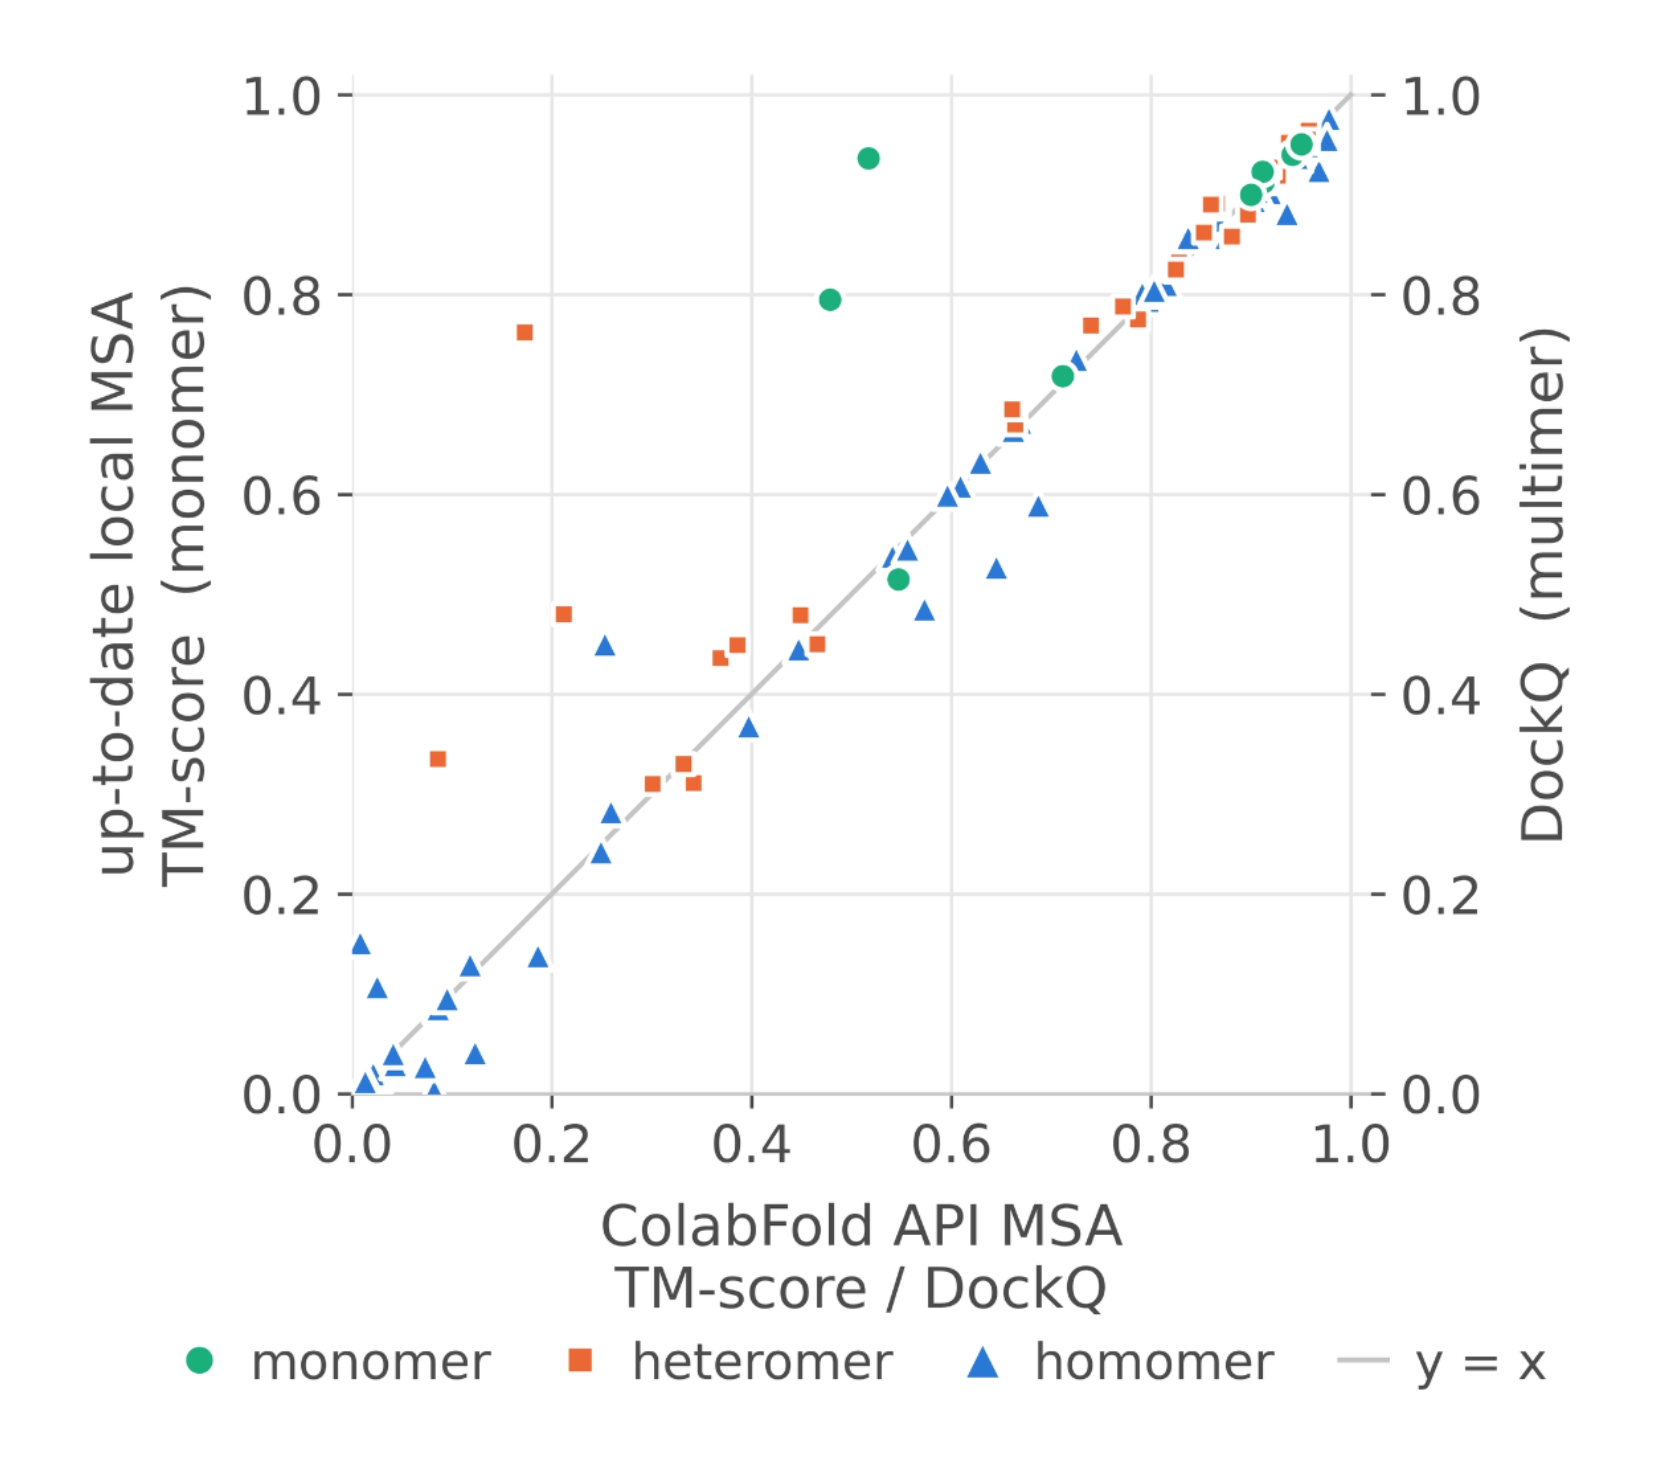

In [9]:
display(Image(data=repo_file("figures/supple_fig2c.png"), width=440))

**Prediction accuracy.** TM-score for monomers and DockQ for multimers.

### Q: What is one unanswered question that you think could be answered using these data? Do you have any recommendations or advice for someone wanting to answer this question?

Proteins whose structures could not be predicted because their MSAs were too shallow may gain additional hits from up-to-date MSA databases, and then be predicted successfully.